# Practical 9 - K-Nearest Neighbours Classification
Dataset: Wine chemistry - classify 178 wines into three cultivars from 13 measurements

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

SEED = 3
HERE = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
def find_data(name):
    """Look for the CSV in the usual places; in Colab, ask for an upload if it is missing."""
    folders = (HERE.parent / "Datasets", HERE / "Datasets", HERE, Path.cwd(),
               Path("/content"), Path("/content/Datasets"), Path("/content/drive/MyDrive"))
    for folder in folders:
        if (folder / name).exists():
            return folder
    try:
        from google.colab import files
        print(f"{name} not found - please choose it in the upload dialog (it is in the Datasets folder).")
        files.upload()
        return Path.cwd()
    except ImportError:
        raise FileNotFoundError(f"Could not find {name}. Put it in a 'Datasets' folder next to this script.")

DATA = find_data("wine.csv")
FIG = HERE / "figures"
FIG.mkdir(exist_ok=True)

wine = pd.read_csv(DATA / "wine.csv")
features = [c for c in wine.columns if c != "wine_class"]
X, y = wine[features], wine["wine_class"]

print("Samples :", len(wine), "| Features :", len(features))
print("Class counts:")
print(y.value_counts().sort_index().to_string())
print("\nAverage of four key measurements per class:")
print(wine.groupby("wine_class")[["alcohol", "flavanoids", "color_intensity", "proline"]].mean().round(3).to_string())

Samples : 178 | Features : 13
Class counts:
wine_class
class_0    59
class_1    71
class_2    48

Average of four key measurements per class:
            alcohol  flavanoids  color_intensity   proline
wine_class                                                
class_0      13.745       2.982            5.528  1115.712
class_1      12.279       2.081            3.087   519.507
class_2      13.154       0.781            7.396   629.896


## 1. Train / test split (75 / 25, stratified)

In [2]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=SEED, stratify=y)
print("Training samples:", len(X_train), "| Test samples:", len(X_test))

Training samples: 133 | Test samples: 45


## 2. Why scaling matters
`proline` is measured in hundreds while `hue` is around 1, so without scaling proline decides every distance.

In [3]:
raw_knn = KNeighborsClassifier(n_neighbors=5).fit(X_train, y_train)
scaled_knn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)).fit(X_train, y_train)
print(f"K=5 accuracy without scaling: {raw_knn.score(X_test, y_test):.4f}")
print(f"K=5 accuracy with scaling   : {scaled_knn.score(X_test, y_test):.4f}")

K=5 accuracy without scaling: 0.6667
K=5 accuracy with scaling   : 0.9778


## 3. Evaluation of the scaled K=5 model

Confusion matrix (rows = actual, columns = predicted):
         class_0  class_1  class_2
class_0       15        0        0
class_1        0       17        1
class_2        0        0       12

Accuracy: 0.9778

              precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        15
     class_1       1.00      0.94      0.97        18
     class_2       0.92      1.00      0.96        12

    accuracy                           0.98        45
   macro avg       0.97      0.98      0.98        45
weighted avg       0.98      0.98      0.98        45



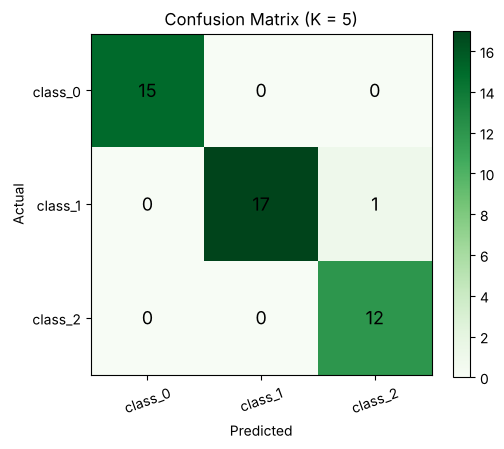

In [4]:
pred = scaled_knn.predict(X_test)
labels = sorted(y.unique())
cm = confusion_matrix(y_test, pred, labels=labels)
print("Confusion matrix (rows = actual, columns = predicted):")
print(pd.DataFrame(cm, index=labels, columns=labels).to_string())
print(f"\nAccuracy: {accuracy_score(y_test, pred):.4f}\n")
print(classification_report(y_test, pred))

fig, ax = plt.subplots(figsize=(5.5, 4.5))
im = ax.imshow(cm, cmap="Greens")
ax.set_xticks(range(3), labels, rotation=20)
ax.set_yticks(range(3), labels)
for i in range(3):
    for j in range(3):
        ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=13)
ax.set(title="Confusion Matrix (K = 5)", xlabel="Predicted", ylabel="Actual")
fig.colorbar(im)
fig.savefig(FIG / "confusion_matrix.png", dpi=120, bbox_inches="tight")
plt.show()

## 4. Choosing K
Every K from 1 to 30 is scored with 5-fold cross-validation on the training data (no peeking at the test set).

In [5]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
ks = list(range(1, 31))
cv_error = []
for k in ks:
    model = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))
    cv_error.append(1 - cross_val_score(model, X_train, y_train, cv=cv).mean())

for k, e in zip(ks, cv_error):
    print(f"K = {k:2d}  ->  cross-validated error = {e:.4f}")

K =  1  ->  cross-validated error = 0.0672
K =  2  ->  cross-validated error = 0.0821
K =  3  ->  cross-validated error = 0.0670
K =  4  ->  cross-validated error = 0.0744
K =  5  ->  cross-validated error = 0.0667
K =  6  ->  cross-validated error = 0.0593
K =  7  ->  cross-validated error = 0.0444
K =  8  ->  cross-validated error = 0.0744
K =  9  ->  cross-validated error = 0.0519
K = 10  ->  cross-validated error = 0.0670
K = 11  ->  cross-validated error = 0.0519
K = 12  ->  cross-validated error = 0.0593
K = 13  ->  cross-validated error = 0.0593
K = 14  ->  cross-validated error = 0.0667
K = 15  ->  cross-validated error = 0.0519
K = 16  ->  cross-validated error = 0.0519
K = 17  ->  cross-validated error = 0.0370
K = 18  ->  cross-validated error = 0.0370
K = 19  ->  cross-validated error = 0.0370
K = 20  ->  cross-validated error = 0.0370
K = 21  ->  cross-validated error = 0.0370
K = 22  ->  cross-validated error = 0.0370
K = 23  ->  cross-validated error = 0.0370
K = 24  -> 

Lowest cross-validated error: 0.037
K values that reach it      : [17, 18, 19, 20, 21, 22, 23, 29]
Chosen K (smallest odd one) : 17


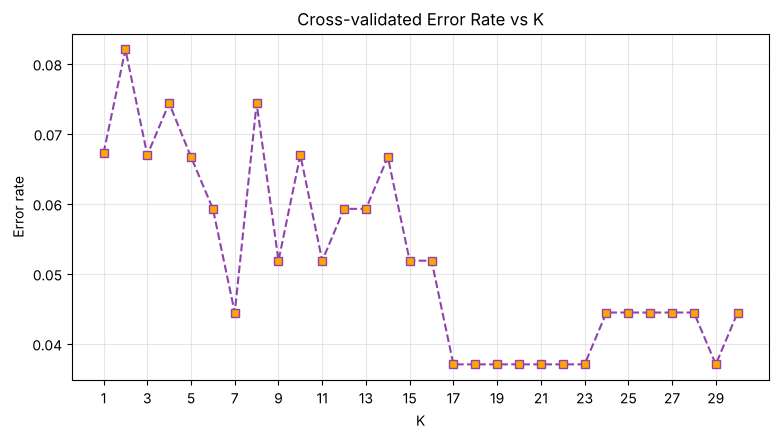

In [6]:
plt.figure(figsize=(9, 4.5))
plt.plot(ks, cv_error, marker="s", linestyle="--", color="#8e44ad", markerfacecolor="orange")
plt.title("Cross-validated Error Rate vs K")
plt.xlabel("K")
plt.ylabel("Error rate")
plt.xticks(ks[::2])
plt.grid(alpha=0.3)
plt.savefig(FIG / "error_vs_k.png", dpi=120, bbox_inches="tight")
plt.show()

lowest = min(cv_error)
tied = [k for k, e in zip(ks, cv_error) if abs(e - lowest) < 1e-12]
odd = [k for k in tied if k % 2 == 1]
best_k = (odd or tied)[0]
print("Lowest cross-validated error:", round(lowest, 4))
print("K values that reach it      :", tied)
print("Chosen K (smallest odd one) :", best_k)

## 5. Final model and a look at one prediction

In [7]:
final = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=best_k)).fit(X_train, y_train)
final_pred = final.predict(X_test)
print(f"Test accuracy with K = {best_k}: {accuracy_score(y_test, final_pred):.4f}")

sample = X_test.iloc[[0]]
scaler, knn = final[0], final[1]
distances, idx = knn.kneighbors(scaler.transform(sample), n_neighbors=5)
print("\nFirst test wine - true class:", y_test.iloc[0], "| predicted:", final_pred[0])
print("Its 5 nearest training wines:")
for d, i in zip(distances[0], idx[0]):
    print(f"   distance {d:.3f}  ->  {y_train.iloc[i]}")

Test accuracy with K = 17: 0.9778

First test wine - true class: class_0 | predicted: class_0
Its 5 nearest training wines:
   distance 1.328  ->  class_0
   distance 1.540  ->  class_0
   distance 1.891  ->  class_0
   distance 2.298  ->  class_0
   distance 2.338  ->  class_0


## 6. Distance metric comparison

In [8]:
for metric in ("euclidean", "manhattan", "chebyshev"):
    m = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=best_k, metric=metric))
    m.fit(X_train, y_train)
    print(f"{metric:<10} test accuracy = {m.score(X_test, y_test):.4f}")

euclidean  test accuracy = 0.9778
manhattan  test accuracy = 0.9556
chebyshev  test accuracy = 0.9333


## 7. Decision regions using two features

Accuracy using only ['flavanoids', 'color_intensity']: 0.9556


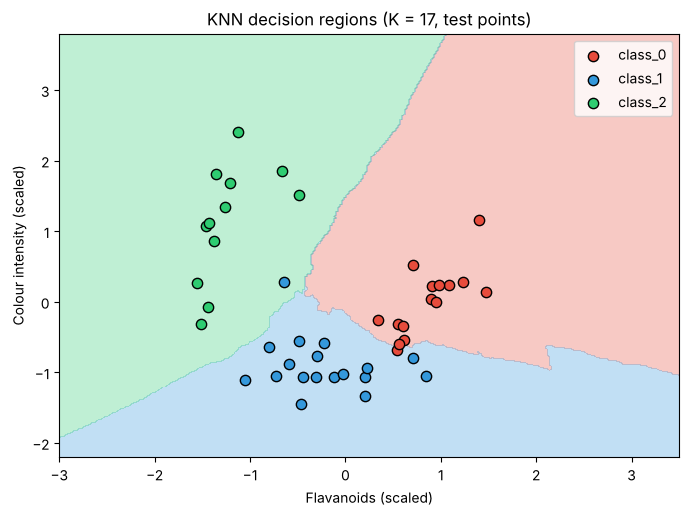

In [9]:
pair = ["flavanoids", "color_intensity"]
sc2 = StandardScaler().fit(X_train[pair])
knn2 = KNeighborsClassifier(n_neighbors=best_k).fit(sc2.transform(X_train[pair]), y_train)
print(f"Accuracy using only {pair}: {knn2.score(sc2.transform(X_test[pair]), y_test):.4f}")

code = {name: i for i, name in enumerate(knn2.classes_)}
gx, gy = np.meshgrid(np.linspace(-3, 3.5, 300), np.linspace(-2.2, 3.8, 300))
zone = knn2.predict(np.c_[gx.ravel(), gy.ravel()])
zone = np.vectorize(code.get)(zone).reshape(gx.shape)

plt.figure(figsize=(8, 5.5))
shades = ["#e74c3c", "#3498db", "#2ecc71"]
plt.contourf(gx, gy, zone, alpha=0.30, levels=[-0.5, 0.5, 1.5, 2.5], colors=shades)
points = sc2.transform(X_test[pair])
for name in knn2.classes_:
    sel = (y_test == name).to_numpy()
    plt.scatter(points[sel, 0], points[sel, 1], color=shades[code[name]], edgecolor="black", s=55, label=name)
plt.title(f"KNN decision regions (K = {best_k}, test points)")
plt.xlabel("Flavanoids (scaled)")
plt.ylabel("Colour intensity (scaled)")
plt.legend()
plt.savefig(FIG / "decision_regions.png", dpi=120, bbox_inches="tight")
plt.show()